## Inicializando dependencias

In [136]:
%run "../3 - Gold/gold_Cadastro.ipynb" # chama tabela gold cadastro

In [137]:
%run "../3 - Gold/gold_Compras.ipynb"  # chama tabela gold compras

In [138]:
%run "../3 - Gold/gold_Perdas.ipynb" # chama tabela gold Perdas

In [139]:
%run "../3 - Gold/gold_Vendas.ipynb" # chama tabela gold Vendas

## Mostra Tabelas

In [140]:
gold_Cadastro.head(3)  # tabela cadastro produtos

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE
0,101,HORTIFRUTI,TOMATE DEBORA KG,7.9,3.2,4.7,TOMATE DEBORA,1,KG
1,102,HORTIFRUTI,BANANA PRATA KG,5.5,2.1,3.4,BANANA PRATA,1,KG
2,103,HORTIFRUTI,ALFACE AMERICANA UN,3.5,1.2,2.3,ALFACE AMERICANA,1,UN


In [141]:
GoldComp.head(3)

,NUM_NOTA_FISCAL,DATA_ENTRADA,FORNECEDOR,COD_PROD,QTD_COMPRADA,VALOR_TOTAL_NOTA,RESPONSAVEL_RECEBIMENTO,N_NF,TOTAL_NOTA,DATA,MES,ANO
0,NF-1006,01/01/2026,CEASA SP,101,55,163.39,MATEUS,1006,163.39,2026-01-01,1,2026
1,NF-1046,01/01/2026,CEASA SP,102,119,335.78,THIAGO,1046,335.78,2026-01-01,1,2026
2,NF-1018,01/01/2026,CEASA SP,103,115,243.92,THIAGO,1018,243.92,2026-01-01,1,2026


In [142]:
silverPerdas.head(3) # tabela perdas de produtos / prejuizo

,DATA_OCORRENCIA,SETOR_ORIGEM,DESCRICAO,COD_PROD,QTD_AVARIADA,PREJUIZO_ESTIMADO,RESPONSAVEL,DATA,ANO,MES,V_PREJUIZO
0,01/01/2026,DEPOSITO,FALTA DE MERCADORIA NO ESTOQUE - SUSPEITA FURTO,601.0,1.10,"R$ 14,18",DIEGO,2026-01-01,2026,1,14.18
1,03/01/2026,HORTI,PODRE DESCARTADO NO LIXO,601.0,6.92,"R$ 100,71",BETAO,2026-01-03,2026,1,100.71
2,04/01/2026,AÇOUGUE,LATA AMASSADA NO DESCARREGAMENTO,1000001.0,7.95,"R$ 98,53",BETAO,2026-01-04,2026,1,98.53


In [143]:
g_id.head(3) # tabela vendas por ID

,ID_TRANSACAO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,900001,5.0,3.94,19.70
1,900002,2.0,34.47,68.94
2,900003,4.0,32.32,129.28


In [144]:
g_caixa.head(3) # tabela vendas por caixa

,PDV_CAIXA,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,CAIXA_01,18793.0,126367.41,253815.99
1,CAIXA_02,19042.0,128519.87,262752.77
2,CAIXA_P,9589.0,64255.47,128483.58


In [145]:
g_operador.head(3)

,OPERADOR,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,CARLOS (GERENTE),933.0,6326.49,12033.08
1,JULIANA,26862.0,180505.69,362366.23
2,N_IDENTIFICADO,849.0,5594.18,10741.34


In [146]:
g_cod.head(3) #tabela vendas por produtos

,COD_PRODUTO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,0.0,3933.0,6326.49,49226.59
1,101.0,1890.0,180505.69,25935.86
2,102.0,2067.0,5594.18,29890.43


In [147]:
g_forma_pagamento.head(3)

,FORMA_PAGTO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,CARTAO_CRED,5819.0,38718.84,77933.86
1,CARTAO_DEB,6143.0,40931.62,84828.50
2,DINHEIRO,5833.0,39611.40,77372.83


In [148]:
g_status.head(3) #tabela venddas por status

,STATUS_VENDA,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,ABERTO,6748.0,52637.00,0.00
1,CANCELADA,6525.0,0.00,0.00
2,CONCLUIDA,27302.0,212733.18,645052.34


In [149]:
g_ano.head(3) # dados vendas no ano (3 mes)

,ANO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,2026,47424.0,319142.75,645052.34


In [150]:
g_mes.head(3) # tabela vendas por mes

,MES,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,1,13150.0,88762.04,177091.79
1,2,11394.0,76773.02,154554.71
2,3,13656.0,92865.81,188314.40


----

## Cria nova tabela

In [151]:
gold_Cadastro['CATEGORIA_BRUTA'].value_counts()

CATEGORIA_BRUTA
HORTIFRUTI            5
ACOUGUE               5
FRIOS E LATICINIOS    4
SECOS E MOLHADOS      3
BEBIDAS               3
PADARIA               2
MERCEARIA             1
Name: count, dtype: int64

In [152]:
print(g_cod.columns.tolist())
print(gold_Cadastro.columns.tolist())

['COD_PRODUTO', 'QTD_VENDIDA', 'PRECO_UNIT_COBRADO', 'TOTAL_PAGO']
['COD_PROD', 'CATEGORIA_BRUTA', 'NOME_PRODUTO', 'VENDA_CADASTRO', 'CUSTO_VENDA', 'MARGEM', 'PROD', 'MEDIDA', 'UNIDADE']


In [153]:
LocalizaProd = g_cod.merge(
    gold_Cadastro,
    left_on='COD_PRODUTO',
    right_on='COD_PROD',
    how='right'
)

In [154]:
LocalizaProd.head(3)

,COD_PRODUTO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE
0,101.0,1890.0,180505.69,25935.86,101,HORTIFRUTI,TOMATE DEBORA KG,7.9,3.2,4.7,TOMATE DEBORA,1,KG
1,102.0,2067.0,5594.18,29890.43,102,HORTIFRUTI,BANANA PRATA KG,5.5,2.1,3.4,BANANA PRATA,1,KG
2,103.0,1831.0,121413.74,26014.99,103,HORTIFRUTI,ALFACE AMERICANA UN,3.5,1.2,2.3,ALFACE AMERICANA,1,UN


In [155]:
LocalizaProd1 = gold_Cadastro.merge(
    g_cod,
    left_on='COD_PROD',
    right_on='COD_PRODUTO',
    how='right'
)

In [156]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,NOME_PRODUTO,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE,COD_PRODUTO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,3933.0,6326.49,49226.59
1,101.0,HORTIFRUTI,TOMATE DEBORA KG,7.9,3.2,4.7,TOMATE DEBORA,1.0,KG,101.0,1890.0,180505.69,25935.86
2,102.0,HORTIFRUTI,BANANA PRATA KG,5.5,2.1,3.4,BANANA PRATA,1.0,KG,102.0,2067.0,5594.18,29890.43


In [157]:
LocalizaProd1 = LocalizaProd1.drop(columns=['COD_PRODUTO','NOME_PRODUTO','PRECO_UNIT_COBRADO'])

In [158]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE,QTD_VENDIDA,TOTAL_PAGO
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3933.0,49226.59
1,101.0,HORTIFRUTI,7.9,3.2,4.7,TOMATE DEBORA,1.0,KG,1890.0,25935.86
2,102.0,HORTIFRUTI,5.5,2.1,3.4,BANANA PRATA,1.0,KG,2067.0,29890.43


In [159]:
LocalizaProd1['v_unitario'] = LocalizaProd1['TOTAL_PAGO'] / LocalizaProd1['QTD_VENDIDA']

In [160]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE,QTD_VENDIDA,TOTAL_PAGO,v_unitario
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3933.0,49226.59,12.516295
1,101.0,HORTIFRUTI,7.9,3.2,4.7,TOMATE DEBORA,1.0,KG,1890.0,25935.86,13.722677
2,102.0,HORTIFRUTI,5.5,2.1,3.4,BANANA PRATA,1.0,KG,2067.0,29890.43,14.460779


In [161]:
LocalizaProd1['v_magem'] = LocalizaProd1['v_unitario'] - LocalizaProd1['CUSTO_VENDA']

In [162]:
LocalizaProd1.head(3)

,COD_PROD,CATEGORIA_BRUTA,VENDA_CADASTRO,CUSTO_VENDA,MARGEM,PROD,MEDIDA,UNIDADE,QTD_VENDIDA,TOTAL_PAGO,v_unitario,v_magem
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3933.0,49226.59,12.516295,NaN
1,101.0,HORTIFRUTI,7.9,3.2,4.7,TOMATE DEBORA,1.0,KG,1890.0,25935.86,13.722677,10.522677
2,102.0,HORTIFRUTI,5.5,2.1,3.4,BANANA PRATA,1.0,KG,2067.0,29890.43,14.460779,12.360779


----

## Crie tabela para grafico

In [163]:
Vendas_graf = LocalizaProd1[['COD_PROD', 'CATEGORIA_BRUTA', 'PROD', 'v_magem', 'v_unitario', 'TOTAL_PAGO', 'QTD_VENDIDA']].copy()

In [164]:
Vendas_graf['QTD_VENDIDA'] = pd.to_numeric(Vendas_graf['QTD_VENDIDA'])

In [165]:
Vendas_graf.head(3)

,COD_PROD,CATEGORIA_BRUTA,PROD,v_magem,v_unitario,TOTAL_PAGO,QTD_VENDIDA
0,NaN,NaN,NaN,NaN,12.516295,49226.59,3933.0
1,101.0,HORTIFRUTI,TOMATE DEBORA,10.522677,13.722677,25935.86,1890.0
2,102.0,HORTIFRUTI,BANANA PRATA,12.360779,14.460779,29890.43,2067.0


### Cria um grafico para produto x margem

<Axes: ylabel='PROD'>

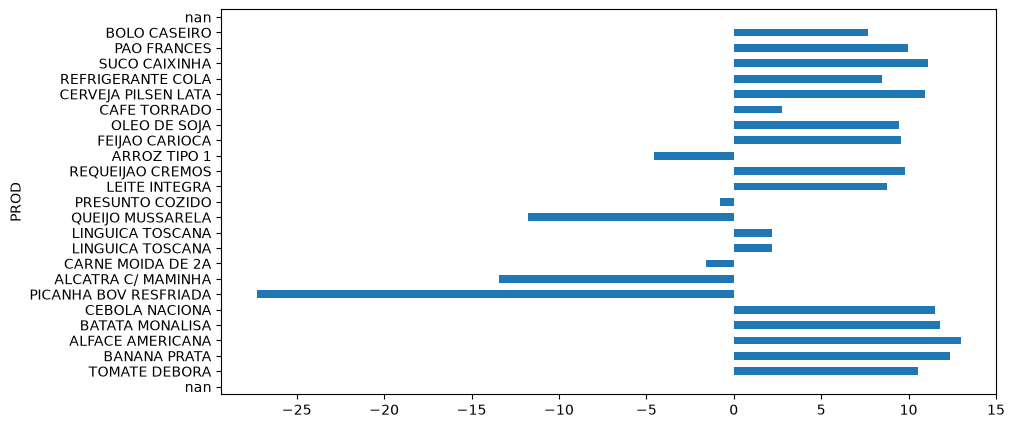

In [166]:
Vendas_graf.plot(
    kind='barh',
    x='PROD',
    y='v_magem',
    figsize=(10, 5),
    legend=False
)

<Axes: ylabel='CATEGORIA_BRUTA'>

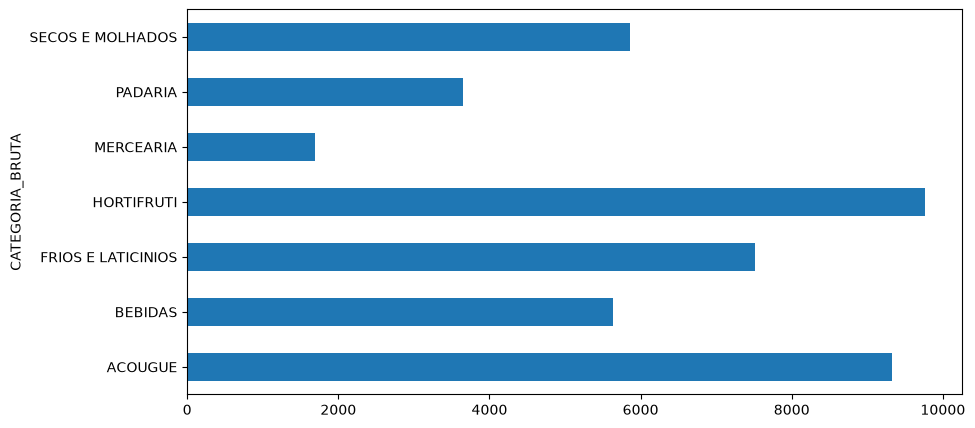

In [167]:
Cons_qtd = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['QTD_VENDIDA'].sum()

Cons_qtd.plot(
    kind='barh',
    x='CATEGORIA_BRUTA',
    y='QTD_VENDIDA',
    figsize=(10, 5),
    legend=False
)

### Cria um grafico para cat x total

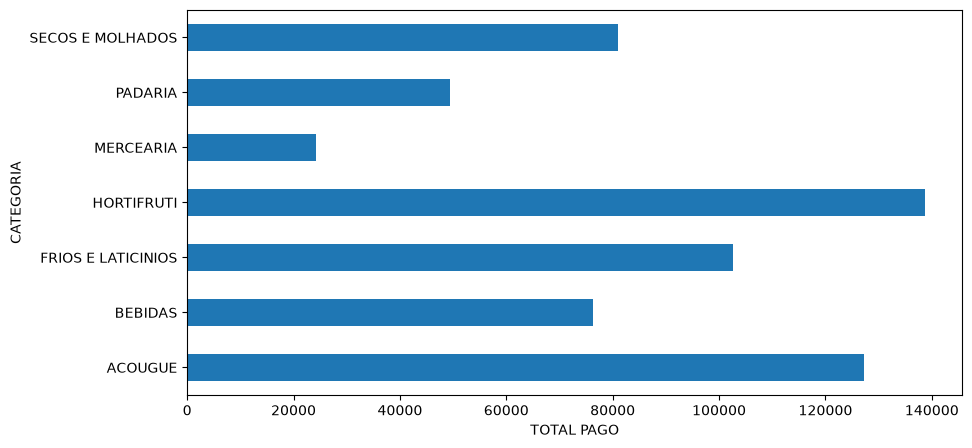

In [168]:
Cons_Unitario = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['TOTAL_PAGO'].sum()


Cons_Unitario.plot(
    kind='barh',
    x='CATEGORIA_BRUTA',
    y='TOTAL_PAGO',
    figsize=(10, 5),
    legend=False
)

plt.xlabel('TOTAL PAGO')
plt.ylabel('CATEGORIA')
plt.show()

### Cria um grafico para cat x a média da margem de lucro

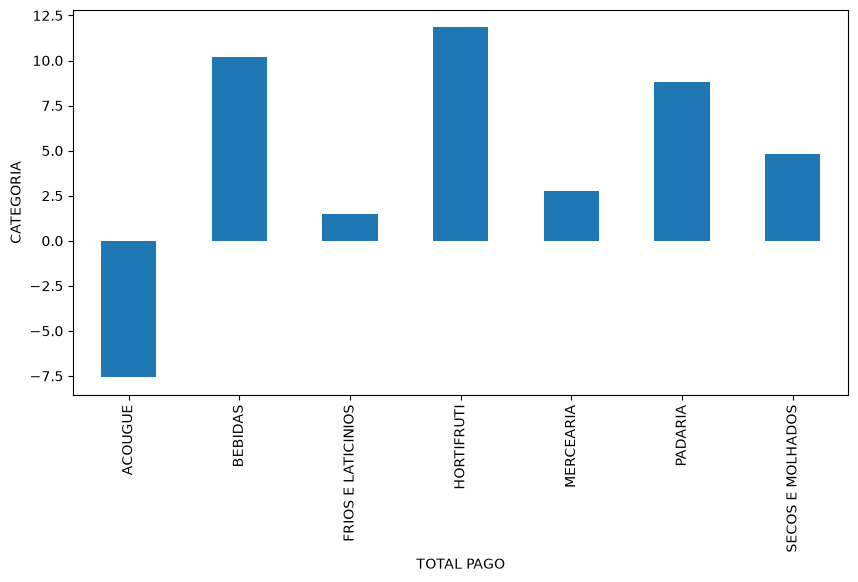

In [169]:
Cons_Unitario_2 = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['v_magem'].mean()


Cons_Unitario_2.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='v_magem',
    figsize=(10, 5),
    legend=False
)

plt.xlabel('TOTAL PAGO')
plt.ylabel('CATEGORIA')
plt.show()

### Cria um grafico para cat x total

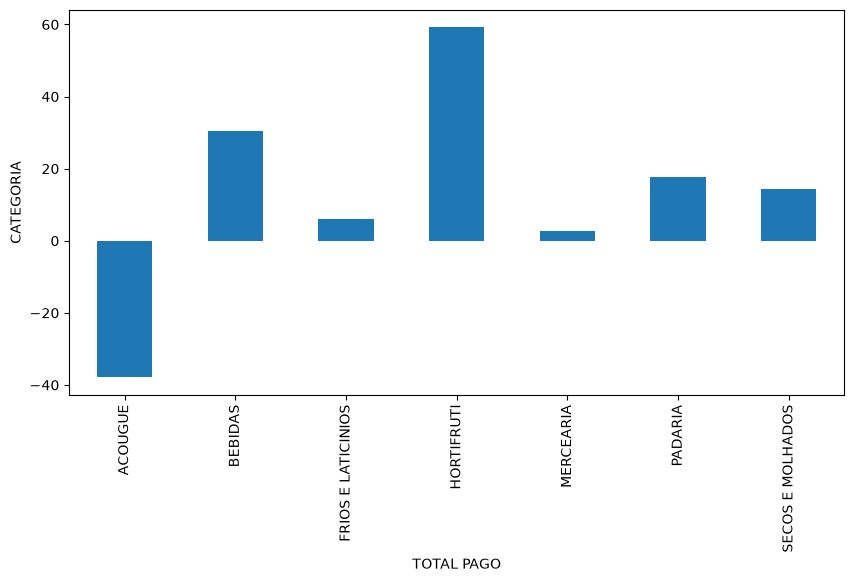

In [170]:
Cons_Unitario_2 = Vendas_graf.groupby(
    'CATEGORIA_BRUTA',
    as_index=False
)['v_magem'].sum()


Cons_Unitario_2.plot(
    kind='bar',
    x='CATEGORIA_BRUTA',
    y='v_magem',
    figsize=(10, 5),
    legend=False
)

plt.xlabel('TOTAL PAGO')
plt.ylabel('CATEGORIA')
plt.show()